# Credit Risk Analysis and Loan Approval Prediction

## 01. Problem statement and objective
* Application Data - what each customer told us / what the bureaus returned at application time.
* Loan Performance - whether each loan later turned out **Good** or **Bad**.

**Objective:** identify the characteristics associated with bad loans, build a baseline classifier that estimates bad-loan risk, and propose a data-driven decision framework (approve / review / decline) for future applicants - while being explicit about the limitations of the data.

**Target:** `bad = 1` (Bad loan), `bad = 0` (Good loan).

## 02. Import libraries and load Excel files

In [2]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_recall_fscore_support)

sns.set_theme(style='whitegrid', context='notebook')
GOOD, BAD = '#2E7D6B', '#C0392B'
pd.set_option('display.max_columns', 50)

FILE = 'Assessment_-_Data_Scientist.xlsx'   
xl = pd.ExcelFile(FILE)
print('Worksheets:', xl.sheet_names)

Worksheets: ['Assignment', 'Application Data', 'Loan Performance']


In [3]:

app  = pd.read_excel(FILE, 'Application Data', dtype={'customer_id': str})
perf = pd.read_excel(FILE, 'Loan Performance')
print('Application Data :', app.shape)
print('Loan Performance :', perf.shape)
display(app.head(3).T)
display(perf.head())

Application Data : (647, 31)
Loan Performance : (1285, 2)


,0,1,2
customer_id,9ece67d6c5,5c2c402094,e6254cad30
amount_requested,500,500,400
birth_date,1991-08-21 00:00:00,1990-07-24 00:00:00,1980-09-13 00:00:00
status,Approved,Approved,Approved
residence_rent_or_own,True,True,True
monthly_rent_amount,0,0,620
bank_account_direct_deposit,True,False,True
application_when,2010-10-16 14:06:05,2010-10-17 13:01:53,2010-10-17 19:52:34
loan_duration,3,6,6
payment_ach,True,True,True


,idLoan,flgGood
0,0DBA6B011D-01,Bad
1,96ACBBA7ED-01,Bad
2,289421D82A-01,Bad
3,9ECE67D6C5-01,Good
4,5C2C402094-01,Bad


In [4]:
# Data dictionary: type, missing, unique values for every application column
dd = pd.DataFrame({'dtype': app.dtypes.astype(str), 'missing': app.isna().sum(),
                   'n_unique': app.nunique(), 'example': app.iloc[0]})
dd

,dtype,missing,n_unique,example
customer_id,object,0,647,9ece67d6c5
amount_requested,int64,0,11,500
birth_date,datetime64[ns],0,624,1991-08-21 00:00:00
status,object,0,1,Approved
residence_rent_or_own,bool,0,2,True
monthly_rent_amount,int64,0,202,0
bank_account_direct_deposit,bool,0,2,True
application_when,datetime64[ns],0,647,2010-10-16 14:06:05
loan_duration,int64,0,7,3
payment_ach,bool,0,2,True


## 03. Data cleaning and joining

In [5]:
print('Duplicate application rows  :', app.duplicated().sum())
print('Duplicate customer_id       :', app.customer_id.duplicated().sum())
print('Application status values   :', app.status.value_counts().to_dict())
print('Duplicate performance rows  :', perf.duplicated().sum())
print('Duplicate idLoan            :', perf.idLoan.duplicated().sum())
print('Outcome values              :', perf.flgGood.value_counts().to_dict())
print()
print('Missing values in application data:')
print(app.isna().sum()[app.isna().sum() > 0])
print()
print('customer_id length distribution:', app.customer_id.str.len().value_counts().to_dict())

Duplicate application rows  : 0
Duplicate customer_id       : 0
Application status values   : {'Approved': 647}
Duplicate performance rows  : 0
Duplicate idLoan            : 0
Outcome values              : {'Good': 769, 'Bad': 516}

Missing values in application data:
payment_amount_approved     20
bank_account_duration        1
other_phone_type           285
how_use_money                2
dtype: int64

customer_id length distribution: {10: 644, 14: 1, 91: 1, 9: 1}



* Every application has status `Approved` -> **no rejected applicants in the data** (selection bias, see section 07).
* No duplicate applications. `other_phone_type` is 44% missing (customer simply did not give a second phone - treat as its own category). `payment_amount_approved` has 20 missing values.
* `customer_id` should be 10 characters, but a few are not - a sign of **Excel corrupting identifiers**.

### 3.2 Understand the performance identifier
`idLoan` looks like `<customer_id>-<loan number>`. Let's split it.

In [6]:
perf['customer_id'] = perf.idLoan.str[:10].str.lower()
perf['loan_seq']    = perf.idLoan.str[11:]
print(perf.loan_seq.value_counts())
print('Unique customers in performance:', perf.customer_id.nunique(), ' | loans:', len(perf))

loan_seq
01    1269
02      16
Name: count, dtype: int64
Unique customers in performance: 1269  | loans: 1285


So the performance sheet has **1,285 loans from 1,269 customers**: 1,269 first loans (`-01`) and 16 repeat loans (`-02`).
That explains part of why it is bigger than the application sheet. Now: how many performance customers have an application here?

In [7]:
perf['in_app'] = perf.customer_id.isin(app.customer_id.str.lower())
print(pd.crosstab(perf.loan_seq, perf.in_app, margins=True))

in_app    False  True   All
loan_seq                   
01          629   640  1269
02            0    16    16
All         629   656  1285


Roughly half of the performance records (629 first loans) have **no application in this dataset**. They can't be used for modelling because we don't know anything about those customers - this is another sign the two files do not describe exactly the same population (different period, product or sample).

The 16 repeat loans (`-02`) belong to customers who *are* in the application file. The application features describe the **first** application, so I link **only the `-01` loan** to each application. Repeat loans are kept aside as a separate observation (a repeat customer's second-loan behaviour is information that wouldn't exist at the time of a first decision).


In [8]:
app['cid'] = app.customer_id.str.lower()
first = perf[perf.loan_seq == '01'][['customer_id', 'idLoan', 'flgGood']].rename(columns={'customer_id': 'cid'})
m0 = app.merge(first, on='cid', how='left')
unmatched = m0[m0.flgGood.isna()][['customer_id', 'amount_requested', 'application_when']]
print('Unmatched after string-safe join:', len(unmatched))
unmatched

Unmatched after string-safe join: 7


,customer_id,amount_requested,application_when
105,41319800000000,800,2010-12-17 07:02:03
207,2101485999999999891963124957726643363108066977...,800,2011-01-18 07:02:26
467,7752f74e8c,300,2011-03-18 11:50:31
512,805206719d,300,2011-03-24 14:10:12
567,902431691,500,2011-04-04 14:28:40
570,689b7958a2,300,2011-04-04 14:57:47
620,e2ef95a963,800,2011-04-13 17:17:57


Three of these are **identifier corruption that can be repaired**:

| Application id | What happened | Performance id |
|---|---|---|
| `41319800000000` | id `00413198E8` was read as scientific notation (413198 x 10^8) | `00413198E8-01` |
| `2101485999999...` (91 digits) | id `2101486E84` read as 2.101486 x 10^90 | `2101486E84-01` |
| `902431691` | leading zero dropped | `0902431691-01` |

These are exactly the "all-digit-and-E" ids that Excel mangles. I repair them with an explicit, documented mapping (not a blind fuzzy match). The remaining 4 have no counterpart in the performance file.

In [9]:
id_fix = {'41319800000000': '00413198e8',
          '2101485999999999891963124957726643363108066977384403893835291012695305676494586357814919168': '2101486e84',
          '902431691': '0902431691'}
app['cid'] = app.customer_id.replace(id_fix).str.lower()

df = app.merge(first, on='cid', how='left', indicator=True)
still_unmatched = df[df._merge == 'left_only']
print('Applications:', len(app), '| matched:', (df._merge == 'both').sum(), '| still unmatched:', len(still_unmatched))
print('Still unmatched ids:', still_unmatched.customer_id.tolist())
print('Their requested amounts / dates look normal:')
display(still_unmatched[['customer_id', 'amount_requested', 'monthly_income_amount', 'application_when']])

Applications: 647 | matched: 643 | still unmatched: 4
Still unmatched ids: ['7752f74e8c', '805206719d', '689b7958a2', 'e2ef95a963']
Their requested amounts / dates look normal:


,customer_id,amount_requested,monthly_income_amount,application_when
467,7752f74e8c,300,3752,2011-03-18 11:50:31
512,805206719d,300,1363,2011-03-24 14:10:12
570,689b7958a2,300,1200,2011-04-04 14:57:47
620,e2ef95a963,800,2400,2011-04-13 17:17:57


**Reconciliation of the 13 "unmatched" applications**

| Step | Count |
|---|---|
| Unmatched when ids are read as numbers (naive) | 13 |
| ...of which fixed by reading `customer_id` as text | 6 |
| ...of which repaired Excel corruption | 3 |
| **Genuinely missing from the performance file** | **4** |

The 4 genuine misses are excluded from modelling (no label) but listed above for follow-up. Their characteristics look ordinary, so excluding them is unlikely to bias results much, but the bank should find out why they have no outcome.

In [10]:
df = df[df._merge == 'both'].drop(columns='_merge').copy()
df['bad'] = (df.flgGood == 'Bad').astype(int)          # 1 = Bad, 0 = Good
print('Modelling dataset:', df.shape)
print(df.flgGood.value_counts().rename('loans').to_frame().assign(share=lambda x: (x.loans/x.loans.sum()).round(3)))

Modelling dataset: (643, 35)
         loans  share
flgGood              
Bad        354  0.551
Good       289  0.449


### 3.4 Other data-quality observations

In [11]:
print('Amount approved differs from amount requested  :', f"{(df.amount_requested != df.amount_approved).mean():.1%}")
print('Duration approved differs from duration requested:', f"{(df.loan_duration != df.duration_approved).mean():.1%}")
print('raw_l2c_score == 50 (looks like a floor / default):', (df.raw_l2c_score <= 100).sum(), 'rows')
print('raw_FICO_* == 222 (floor / default value)        :', (df[['raw_FICO_telecom','raw_FICO_retail','raw_FICO_bank_card','raw_FICO_money']] == 222).sum().to_dict())
print('Application date range:', df.application_when.min().date(), 'to', df.application_when.max().date())
print('Monthly income range  :', df.monthly_income_amount.min(), '-', df.monthly_income_amount.max())

Amount approved differs from amount requested  : 29.1%
Duration approved differs from duration requested: 19.8%
raw_l2c_score == 50 (looks like a floor / default): 8 rows
raw_FICO_* == 222 (floor / default value)        : {'raw_FICO_telecom': 1, 'raw_FICO_retail': 1, 'raw_FICO_bank_card': 1, 'raw_FICO_money': 1}
Application date range: 2010-10-16 to 2011-04-17
Monthly income range  : 300 - 19392


* The lender changed the amount/duration on ~29% / ~20% of loans. Those *approved* terms are decided by the lender, so I treat them as **decision outputs, not inputs**, and exclude them from the model.
* Score fields contain placeholder-looking floor values (50 / 222) - these likely mean "no score returned". They are kept (trees and logistic regression can cope) but flagged.
* The data window is about six months (Oct-2010 to Apr-2011), with no loan origination date or observation-length field in the performance table.

## 04. Exploratory Data Analysis (EDA)

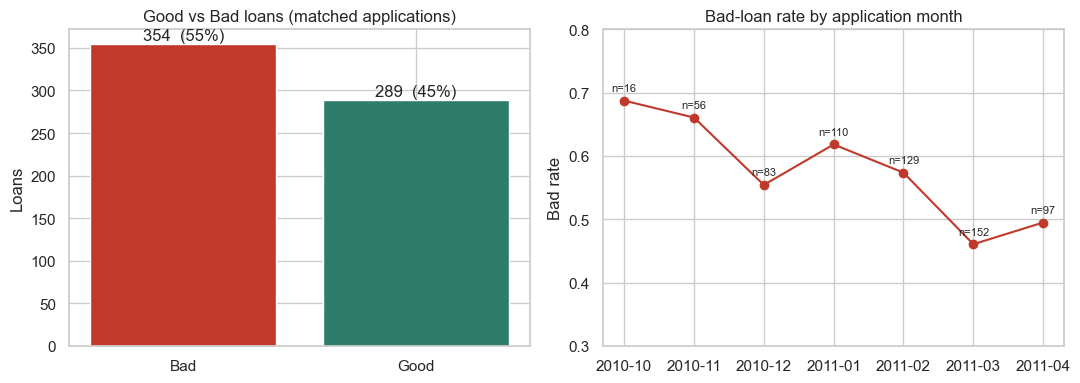

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
vc = df.flgGood.value_counts()
ax[0].bar(vc.index, vc.values, color=[BAD if i == 'Bad' else GOOD for i in vc.index])
for i, v in enumerate(vc.values): ax[0].text(i, v + 5, f'{v}  ({v/vc.sum():.0%})', ha='center')
ax[0].set_title('Good vs Bad loans (matched applications)'); ax[0].set_ylabel('Loans')

df['month'] = df.application_when.dt.to_period('M').astype(str)
mm = df.groupby('month').bad.agg(['mean', 'count'])
ax[1].plot(mm.index, mm['mean'], marker='o', color=BAD)
for i, (r, c) in enumerate(zip(mm['mean'], mm['count'])): ax[1].text(i, r + .015, f'n={c}', ha='center', fontsize=8)
ax[1].set_ylim(0.3, 0.8); ax[1].set_title('Bad-loan rate by application month'); ax[1].set_ylabel('Bad rate')
plt.tight_layout(); plt.show()

**The base bad rate is about 55%** - very high for a lender, so this is clearly a high-risk, short-term, small-dollar loan book. Bad rate drifts down from ~69% (Oct-2010) to ~46-49% (Mar/Apr-2011). That can be a real improvement in underwriting, **or** an artefact: later loans have had less time to go bad. Without an observation window per loan we can't tell (see limitations).

In [14]:
# Feature engineering used both for EDA and for the model
df['age'] = (df.application_when - df.birth_date).dt.days / 365.25
ppm = {'Weekly': 52/12, 'Bi-weekly': 26/12, 'Semi-monthly': 2, 'Monthly': 1}     # payments per month
df['monthly_payment']  = df.payment_amount * df.payment_frequency.map(ppm)
df['payment_to_income'] = df.monthly_payment / df.monthly_income_amount
df['rent_to_income']    = df.monthly_rent_amount / df.monthly_income_amount
df['request_to_income'] = df.amount_requested / df.monthly_income_amount
df['purpose']     = (df.how_use_money.fillna('Other').str.split(' ').str[0]
                       .replace({"Won't": 'Other', 'Gifts': 'Other', 'School': 'Other', 'Rent': 'Other'}))
df['other_phone'] = df.other_phone_type.fillna('None given')
df['owns_home']   = df.residence_rent_or_own.astype(int)
df['direct_deposit'] = df.bank_account_direct_deposit.astype(int)

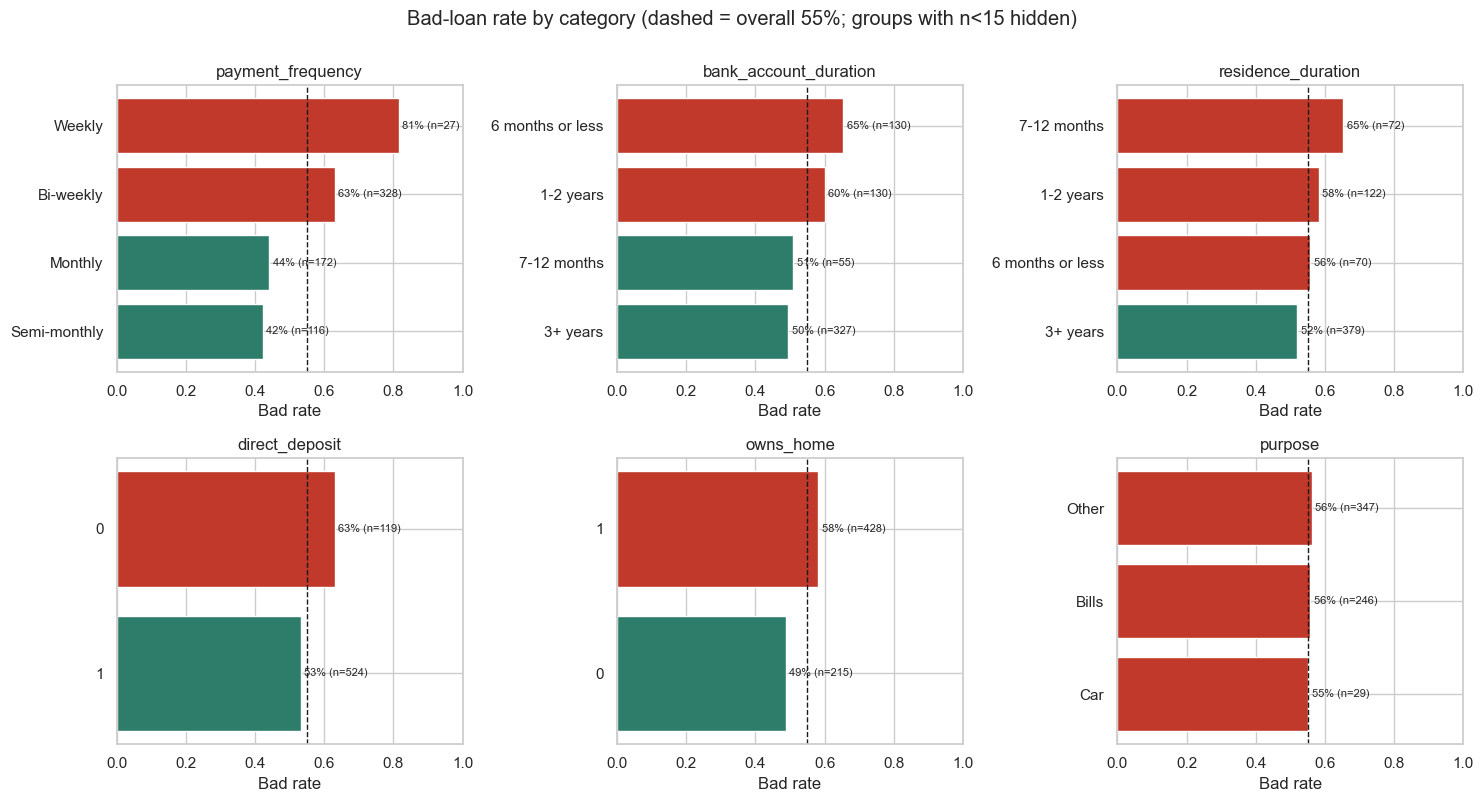

In [15]:
cats = ['payment_frequency', 'bank_account_duration', 'residence_duration', 'direct_deposit', 'owns_home', 'purpose']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
base = df.bad.mean()
for ax, c in zip(axes.ravel(), cats):
    g = df.groupby(c).bad.agg(['mean', 'count']).query('count >= 15').sort_values('mean')
    ax.barh(g.index.astype(str), g['mean'], color=[BAD if v > base else GOOD for v in g['mean']])
    ax.axvline(base, color='k', ls='--', lw=1)
    for y, (r, n) in enumerate(zip(g['mean'], g['count'])): ax.text(r + .01, y, f'{r:.0%} (n={n})', va='center', fontsize=8)
    ax.set_xlim(0, 1); ax.set_title(c); ax.set_xlabel('Bad rate')
plt.suptitle('Bad-loan rate by category (dashed = overall %.0f%%; groups with n<15 hidden)' % (base*100), y=1.0)
plt.tight_layout(); plt.show()

**Categorical patterns**
* **Payment frequency** is the strongest category: weekly payers go bad ~81% of the time, bi-weekly ~63%, whereas monthly (~44%) and semi-monthly (~42%) are much better.
* **Bank account duration:** accounts of 6 months or less are worst (~65%) vs 3+ years (~50%).
* **Direct deposit:** no direct deposit -> ~63% bad vs ~53% with direct deposit.
* Counter-intuitively, home owners are slightly *worse* than renters in this sample.

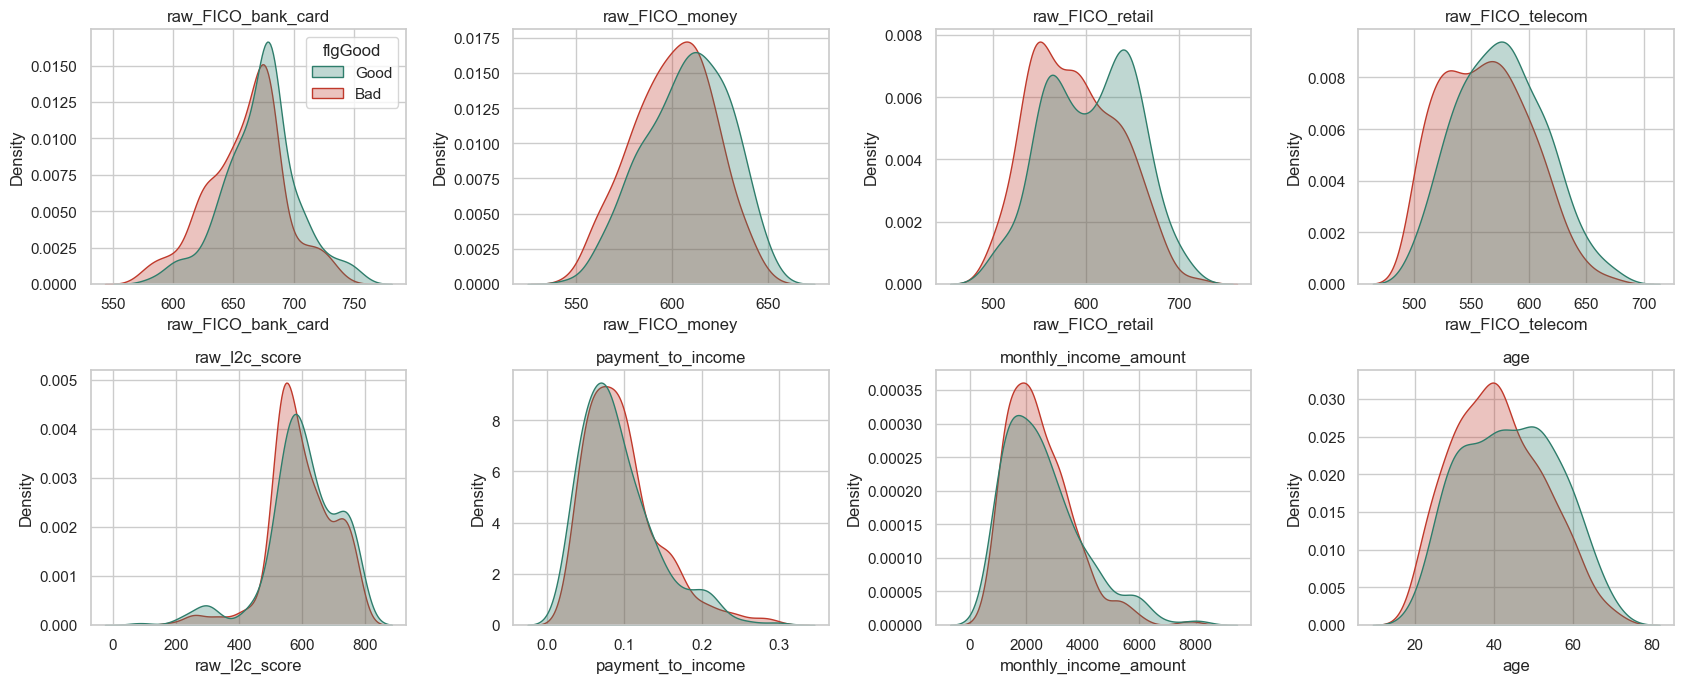

In [18]:
nums = ['raw_FICO_bank_card', 'raw_FICO_money', 'raw_FICO_retail', 'raw_FICO_telecom', 'raw_l2c_score',
        'payment_to_income', 'monthly_income_amount', 'age']
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.ravel(), nums):
    lo, hi = df[c].quantile([.01, .99])
    s = df[(df[c] >= lo) & (df[c] <= hi)]
    sns.kdeplot(data=s, x=c, hue='flgGood', palette={'Good': GOOD, 'Bad': BAD}, common_norm=False, fill=True, alpha=.3, ax=ax, legend=(c == nums[0]))
    ax.set_title(c)
plt.tight_layout(); plt.show()

In [19]:
# Bad rate by quartile of each numeric variable (monotonic trend = useful risk driver)
rows = []
for c in nums + ['rent_to_income', 'request_to_income']:
    q = pd.qcut(df[c], 4, duplicates='drop')
    r = df.groupby(q).bad.mean().values
    rows.append([c] + list(np.round(r, 2)) + [np.round(r[-1] - r[0], 2)])
qt = pd.DataFrame(rows, columns=['feature', 'Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)', 'Q4 - Q1'])
qt.sort_values('Q4 - Q1')

,feature,Q1 (lowest),Q2,Q3,Q4 (highest),Q4 - Q1
0,raw_FICO_bank_card,0.66,0.61,0.53,0.36,-0.30
2,raw_FICO_retail,0.68,0.58,0.53,0.41,-0.27
1,raw_FICO_money,0.65,0.58,0.57,0.40,-0.25
3,raw_FICO_telecom,0.69,0.54,0.52,0.46,-0.23
7,age,0.61,0.61,0.54,0.44,-0.17
4,raw_l2c_score,0.60,0.58,0.51,0.52,-0.08
6,monthly_income_amount,0.53,0.60,0.56,0.50,-0.03
5,payment_to_income,0.52,0.53,0.61,0.54,0.02
8,rent_to_income,0.56,0.60,0.46,0.58,0.02
9,request_to_income,0.50,0.53,0.62,0.55,0.04


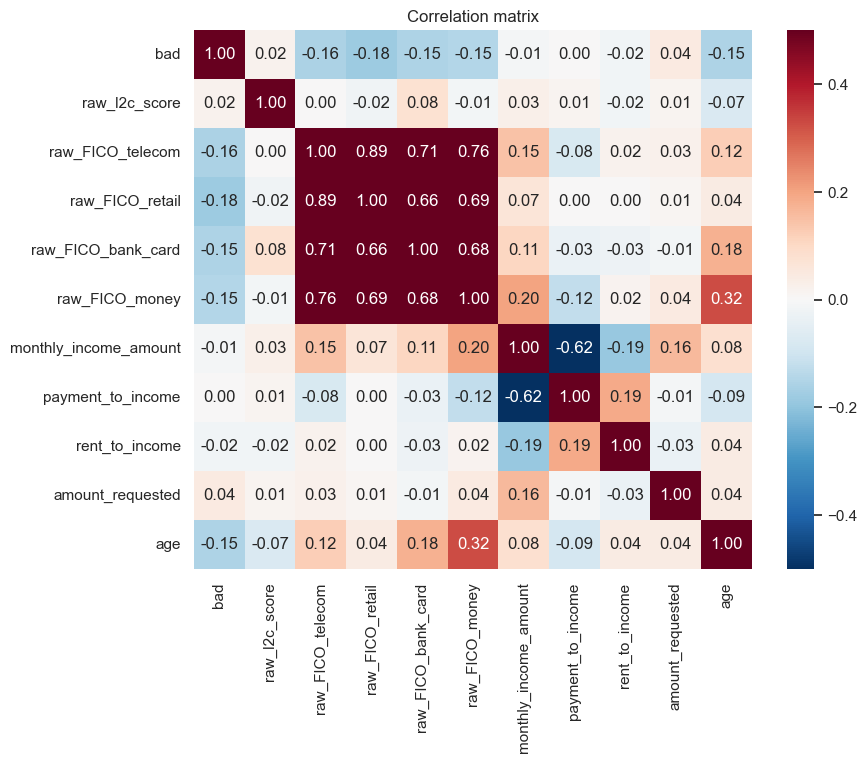

In [20]:
plt.figure(figsize=(9, 7))
corr_cols = ['bad', 'raw_l2c_score', 'raw_FICO_telecom', 'raw_FICO_retail', 'raw_FICO_bank_card', 'raw_FICO_money',
             'monthly_income_amount', 'payment_to_income', 'rent_to_income', 'amount_requested', 'age']
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-.5, vmax=.5)
plt.title('Correlation matrix'); plt.show()

**Numeric patterns**
* The **external score fields** are directionally right: higher `raw_FICO_bank_card`, `raw_FICO_money` and `raw_FICO_retail` -> fewer bad loans (top quartile ~36-41% bad vs ~65-68% bottom quartile).
* **Lower payment amounts** are associated with fewer bad loans; `raw_l2c_score` shows only a weak trend.
* **Age** also shows a gradient (youngest quartile ~61% bad vs oldest ~44%), but age is fairness-sensitive so it is not used in the model.
* No single variable separates good from bad cleanly - the differences are moderate and income / ratio features show almost no trend. **Expect a modest model.**

## 05. Feature engineering and model training



In [21]:
num_feats = ['amount_requested', 'monthly_income_amount', 'monthly_rent_amount', 'loan_duration', 'num_payments',
             'payment_amount', 'payment_to_income', 'rent_to_income', 'request_to_income',
             'raw_l2c_score', 'raw_FICO_telecom', 'raw_FICO_retail', 'raw_FICO_bank_card', 'raw_FICO_money',
             'owns_home', 'direct_deposit']
cat_feats = ['payment_frequency', 'residence_duration', 'bank_account_duration', 'email_duration',
             'home_phone_type', 'other_phone', 'purpose']
X, y = df[num_feats + cat_feats], df.bad

def make_pre(nums, cats):
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), nums),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cats)])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print('Train:', X_train.shape, 'bad rate %.3f' % y_train.mean(), '| Test:', X_test.shape, 'bad rate %.3f' % y_test.mean())

logit = Pipeline([('pre', make_pre(num_feats, cat_feats)), ('clf', LogisticRegression(C=0.3, max_iter=2000))])
rf    = Pipeline([('pre', make_pre(num_feats, cat_feats)),
                  ('clf', RandomForestClassifier(n_estimators=500, min_samples_leaf=5, random_state=42))])
logit.fit(X_train, y_train); rf.fit(X_train, y_train)

Train: (482, 23) bad rate 0.550 | Test: (161, 23) bad rate 0.553


Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['amount_requested',
                                                   'monthly_income_amount',
                                                   'monthly_rent_amount',
                                                   'loan_duration',
                                                   'num_payments',
                                                   'payment_amount',
                                                   'payment_to_income',
                                                   'rent_to_income',
                                                   'request_to_income',
                                                   'raw_l2c_score',
                                                   'raw_FICO_telecom',
                                                   'raw_FICO_retail',
                                                   'raw_FICO_bank_card',
                                                   'raw_FICO_money',
                                                   'owns_home',
                                                   'direct_deposit']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['payment_frequency',
                                                   'residence_duration',
                                                   'bank_account_duration',
                                                   'email_duration',
                                                   'home_phone_type',
                                                   'other_phone',
                                                   'purpose'])])),
                ('clf',
                 RandomForestClassifier(min_samples_leaf=5, n_estimators=500,
                                        random_state=42))])

Because the dataset is small (643 loans), a single 25% test split is noisy (about 161 loans). I therefore also report **5-fold cross-validated** performance, which uses every loan as a test case once.

## 06. Model evaluation

In [22]:
skf = StratifiedKFold(5, shuffle=True, random_state=42)
res = {}
for name, mdl in [('Logistic Regression', logit), ('Random Forest', rf)]:
    cv_p = cross_val_predict(mdl, X, y, cv=skf, method='predict_proba')[:, 1]
    ho_p = mdl.predict_proba(X_test)[:, 1]
    res[name] = dict(cv=cv_p, ho=ho_p)
    print(f'{name:20s} | 5-fold CV ROC-AUC = {roc_auc_score(y, cv_p):.3f} | hold-out ROC-AUC = {roc_auc_score(y_test, ho_p):.3f}')

# Time-based check: train on the earliest 75% of applications, test on the latest 25%
d_sorted = df.sort_values('application_when'); cut = int(len(d_sorted) * .75)
tm = Pipeline([('pre', make_pre(num_feats, cat_feats)), ('clf', LogisticRegression(C=0.3, max_iter=2000))])
tm.fit(d_sorted[num_feats + cat_feats].iloc[:cut], d_sorted.bad.iloc[:cut])
print('Logistic Regression | out-of-time ROC-AUC (train early -> test latest 25%%) = %.3f' %
      roc_auc_score(d_sorted.bad.iloc[cut:], tm.predict_proba(d_sorted[num_feats + cat_feats].iloc[cut:])[:, 1]))

# Sensitivity: add age + zip-region (fairness-sensitive) to see whether they would add much
df['zip3'] = df.address_zip.astype(str).str[:3]
s_num, s_cat = num_feats + ['age'], cat_feats + ['zip3']
sens = Pipeline([('pre', make_pre(s_num, s_cat)), ('clf', LogisticRegression(C=0.3, max_iter=2000))])
p = cross_val_predict(sens, df[s_num + s_cat], y, cv=skf, method='predict_proba')[:, 1]
print('Sensitivity: LR + age + zip3 5-fold CV ROC-AUC = %.3f (vs %.3f without)' % (roc_auc_score(y, p), roc_auc_score(y, res['Logistic Regression']['cv'])))

Logistic Regression  | 5-fold CV ROC-AUC = 0.627 | hold-out ROC-AUC = 0.573
Random Forest        | 5-fold CV ROC-AUC = 0.640 | hold-out ROC-AUC = 0.566
Logistic Regression | out-of-time ROC-AUC (train early -> test latest 25%) = 0.647
Sensitivity: LR + age + zip3 5-fold CV ROC-AUC = 0.624 (vs 0.627 without)



**Cost of errors (CV, threshold 0.50):** 110 of 354 bad loans (31%) are wrongly classed as good; lowering the cut-off to 0.40 cuts that to 50 (14%) but then 213 of 289 good loans (74%) get flagged. This is the trade-off the bank must price. Random Forest is similar in cross-validation (0.64 vs 0.63) and no better on the hold-out set, so the extra complexity is not justified; I keep Logistic Regression as the baseline (interpretable, stable). The single hold-out AUC (~0.57) is lower than the CV figure because 161 loans is a very noisy test - treat the true AUC as roughly **0.57-0.65**. Adding age and zip does not help materially, so there is no performance reason to use those sensitive fields.

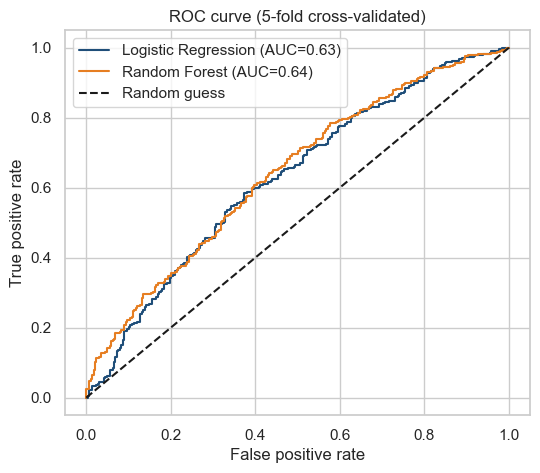

In [23]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, c in [('Logistic Regression', '#1F4E79'), ('Random Forest', '#E67E22')]:
    fpr, tpr, _ = roc_curve(y, res[name]['cv'])
    ax.plot(fpr, tpr, color=c, label=f"{name} (AUC={roc_auc_score(y, res[name]['cv']):.2f})")
ax.plot([0, 1], [0, 1], 'k--', label='Random guess'); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('ROC curve (5-fold cross-validated)'); ax.legend(); plt.show()

### Classification metrics and the cost of a missed bad loan
At the default 0.5 cut-off, and at a lower cut-off that catches more bad loans. A **false negative = a bad loan predicted good** - the expensive error.

In [24]:
def report(y_true, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    pr, rc, f1, _ = precision_recall_fscore_support(y_true, pred, average='binary')
    return dict(threshold=thr, precision_bad=round(pr, 3), recall_bad=round(rc, 3), f1_bad=round(f1, 3),
                accuracy=round((tp + tn) / len(y_true), 3), TN=tn, FP=fp, FN_bad_called_good=fn, TP=tp)

p_cv = res['Logistic Regression']['cv']
print('Logistic Regression - cross-validated predictions (all 643 loans)')
display(pd.DataFrame([report(y, p_cv, t) for t in [0.40, 0.50, 0.55, 0.60]]).set_index('threshold'))
print('Base rate: always predicting BAD gives precision = %.3f, recall = 1.0' % y.mean())

Logistic Regression - cross-validated predictions (all 643 loans)


,precision_bad,recall_bad,f1_bad,accuracy,TN,FP,FN_bad_called_good,TP
threshold,,,,,,,,
0.40,0.588,0.859,0.698,0.591,76,213,50,304
0.50,0.622,0.689,0.654,0.599,141,148,110,244
0.55,0.646,0.599,0.622,0.599,173,116,142,212
0.60,0.660,0.483,0.558,0.579,201,88,183,171


Base rate: always predicting BAD gives precision = 0.551, recall = 1.0


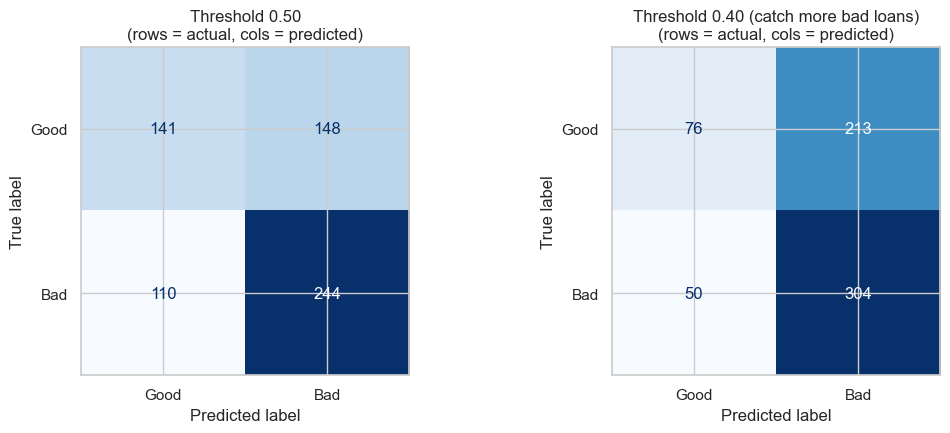

              precision    recall  f1-score   support

        Good       0.56      0.49      0.52       289
         Bad       0.62      0.69      0.65       354

    accuracy                           0.60       643
   macro avg       0.59      0.59      0.59       643
weighted avg       0.60      0.60      0.59       643



In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a_, (t, ttl) in zip(ax, [(0.5, 'Threshold 0.50'), (0.4, 'Threshold 0.40 (catch more bad loans)')]):
    cm = confusion_matrix(y, (p_cv >= t).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['Good', 'Bad']).plot(ax=a_, cmap='Blues', colorbar=False)
    a_.set_title(ttl + '\n(rows = actual, cols = predicted)')
plt.tight_layout(); plt.show()

print(classification_report(y, (p_cv >= 0.5).astype(int), target_names=['Good', 'Bad']))

In [26]:
# Hold-out test set (161 loans) for reference
print('Hold-out test set, Logistic Regression @0.50')
print(classification_report(y_test, (res['Logistic Regression']['ho'] >= .5).astype(int), target_names=['Good', 'Bad']))
tn, fp, fn, tp = confusion_matrix(y_test, (res['Logistic Regression']['ho'] >= .5).astype(int)).ravel()
print(f'Bad loans wrongly classed as good on hold-out: {fn} of {fn + tp} ({fn/(fn+tp):.0%})')

Hold-out test set, Logistic Regression @0.50
              precision    recall  f1-score   support

        Good       0.52      0.43      0.47        72
         Bad       0.59      0.67      0.63        89

    accuracy                           0.57       161
   macro avg       0.56      0.55      0.55       161
weighted avg       0.56      0.57      0.56       161

Bad loans wrongly classed as good on hold-out: 29 of 89 (33%)


### Which characteristics drive predicted risk?
Coefficients of the standardised Logistic Regression (positive = higher bad-loan risk, holding the other fields constant).

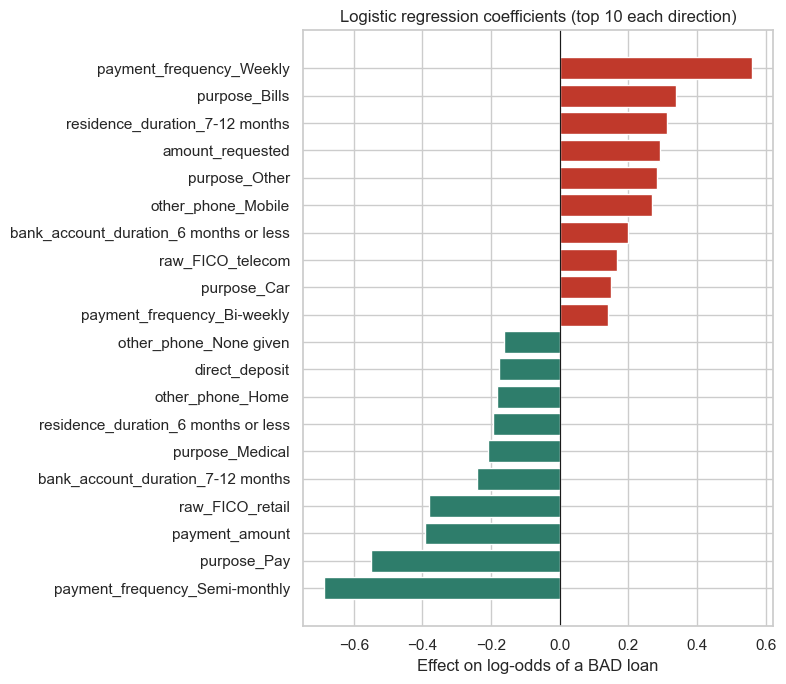

In [27]:
logit.fit(X, y)    # refit on all data for interpretation only
names = logit.named_steps['pre'].get_feature_names_out()
coef = pd.Series(logit.named_steps['clf'].coef_[0], index=[n.split('__')[1] for n in names]).sort_values()
top = pd.concat([coef.head(10), coef.tail(10)])
plt.figure(figsize=(8, 7))
plt.barh(top.index, top.values, color=[GOOD if v < 0 else BAD for v in top.values])
plt.axvline(0, color='k', lw=.8); plt.title('Logistic regression coefficients (top 10 each direction)')
plt.xlabel('Effect on log-odds of a BAD loan'); plt.tight_layout(); plt.show()

Key drivers: **weekly / bi-weekly payment frequency** and short bank-account tenure increase risk; higher **bank-card, money and retail scores** and monthly / semi-monthly pay cycles reduce it. These agree with the EDA, which is reassuring. Note these are associations, not causes: payment frequency probably reflects the kind of job / income stability.

## 07. Business recommendations and limitations
### 7.1 How could the bank use the predictions?
Risk bands based on predicted bad-loan probability, using **cross-validated** probabilities. Cut-offs below are *illustrative* - they should be set by the bank's costs and risk appetite, not by this analysis.

,loans,avg_predicted,actual_bad_rate
risk_decile,,,
1,65,0.265,0.292
2,64,0.364,0.500
3,64,0.438,0.438
4,64,0.485,0.578
5,65,0.530,0.462
6,64,0.576,0.609
7,64,0.627,0.609
8,64,0.674,0.641
9,64,0.731,0.703


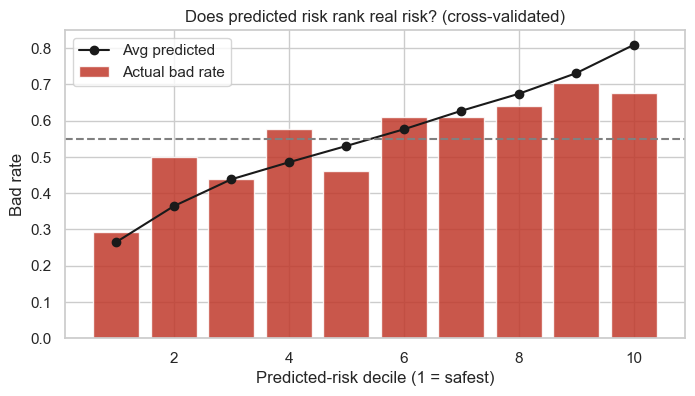

In [28]:
df['p_bad'] = p_cv
df['risk_decile'] = pd.qcut(df.p_bad, 10, labels=False) + 1
dec = df.groupby('risk_decile').agg(loans=('bad', 'size'), avg_predicted=('p_bad', 'mean'), actual_bad_rate=('bad', 'mean')).round(3)
display(dec)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dec.index, dec.actual_bad_rate, color=BAD, alpha=.85, label='Actual bad rate')
ax.plot(dec.index, dec.avg_predicted, 'ko-', label='Avg predicted'); ax.axhline(y.mean(), ls='--', color='grey')
ax.set_xlabel('Predicted-risk decile (1 = safest)'); ax.set_ylabel('Bad rate'); ax.set_title('Does predicted risk rank real risk? (cross-validated)')
ax.legend(); plt.show()

In [29]:
# Three-band framework (illustrative): safest 30% / middle 40% / riskiest 30% by predicted risk
lo, hi = df.p_bad.quantile([.30, .70])
df['band'] = pd.cut(df.p_bad, [-1, lo, hi, 2], labels=['Low risk -> consider approval', 'Medium -> manual review', 'High -> enhanced checks / decline'])
band = df.groupby('band').agg(loans=('bad', 'size'), actual_bad_rate=('bad', 'mean'), avg_requested=('amount_requested', 'mean')).round(3)
band['share_of_loans'] = (band.loans / len(df)).round(2)
display(band)
print(f'Cut-offs used: p_bad <= {lo:.2f} (low), >= {hi:.2f} (high)')

,loans,actual_bad_rate,avg_requested,share_of_loans
band,,,,
Low risk -> consider approval,193,0.409,582.124,0.3
Medium -> manual review,257,0.564,589.105,0.4
High -> enhanced checks / decline,193,0.674,627.979,0.3


Cut-offs used: p_bad <= 0.47 (low), >= 0.65 (high)


**Reading the bands:** the safest 30% still goes bad at roughly 40-45% and the riskiest 30% at roughly 65-70% - a clear *ranking* but **no band is "safe"** in an absolute sense. Even the best band loses money unless pricing covers a ~40%+ default rate.

### 7.2 Suggested decision framework
| Band | Suggested action |
|---|---|
| Low predicted risk | Approve, subject to affordability and policy checks; candidate for larger limits / lower price **only after** validation |
| Medium | Manual review: verify income and employment, confirm direct deposit, consider a lower amount or monthly pay cycle |
| High | Enhanced checks or decline (e.g. weekly pay cycle + short bank history + low bank-card score) |

Thresholds should be chosen from the **expected-loss trade-off**: `cost of a missed bad loan x missed bad loans` vs `margin lost on a rejected good loan x rejected good loans`, then validated in a controlled test (champion/challenger, or approve a small random sample of "high-risk" applicants).

### 7.3 Why the model is not enough by itself
| Limitation | Evidence from this data | Why it matters | Improvement |
|---|---|---|---|
| **Only approved applicants** | All 647 rows are `Approved` | **Selection bias**: model learns only from people the old policy accepted; can't say how rejected applicants would have behaved | Get governed data on declined applications; reject inference; small controlled approvals |
| **Weak predictive power** | CV ROC-AUC ~0.63; out-of-time ~0.65 | Most variation in outcomes is not explained by available fields | Add stronger data (below) |
| **Small, short sample** | 643 labelled loans, ~6 months | Wide uncertainty; no economic cycle | Multi-year data |
| **Linking problems** | 13 "unmatched" -> 6 type errors, 3 Excel-corrupted ids, 4 genuine | Silent drops would have hidden a data pipeline issue | Enforce text ids, validate keys, report match rates |
| **Performance file doesn't match applications** | 1,285 loans / 1,269 customers vs 647 applications; 629 first loans have no application | Different period/sample, or missing applications | Reconcile sources |
| **Repeat loans** | 16 second loans (`-02`) | Same customer, multiple outcomes; excluded to avoid leakage | Model first-time and repeat borrowers separately |
| **Outcome definition & timing** | Good/Bad flag, no origination date, no observation period | Newer loans had less time to go bad -> bad rate trend (69% -> 46%) may be censoring | Add loan dates, days past due, observation window |
| **High base rate / class balance** | 55% bad | Accuracy is misleading; use precision / recall / F1 / confusion matrix | Cost-based thresholds |
| **Possible biased predictors** | age, zip, bank routing available | Proxy discrimination risk | Fairness and compliance review; excluded here |
| **No business costs** | No interest, fees, losses | Optimal cut-off cannot be derived | Profit and loss per loan |
| **Placeholder score values** | 50 / 222 floors | May mean "no score" | Clarify with data owner |


### 7.5 Conclusion
* Bad loans are common (**~55%**) in this book, so risk-based *pricing and limits* matter as much as approve/decline.
* Payment frequency, bank-account tenure, direct deposit and the bureau-style scores are the most useful signals.
* A baseline Logistic Regression ranks risk moderately (AUC ~0.63). It is suitable as a **decision-support tool** (triage into review bands), **not** as an automatic approve/decline engine.
* Before deployment: fix data pipelines, collect declined-applicant and time-stamped performance data, run fairness checks and pilot the policy.